# Lab Assignment 2 - Scientific Computing Lab

## Submitted by - Naman Jain, SC26M013

New positions: [0.499375 1.00875  1.493125]
New velocities: [-0.03746875  0.1245625  -0.21215625]
Half Time Step: [-0.0125  0.175  -0.1375]


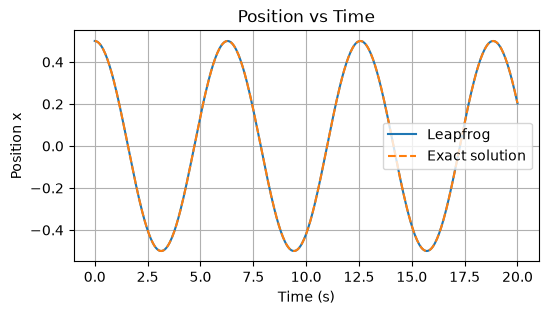

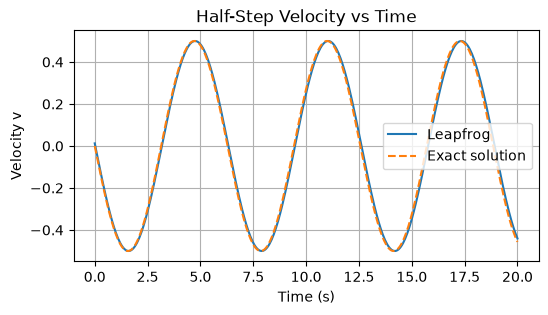

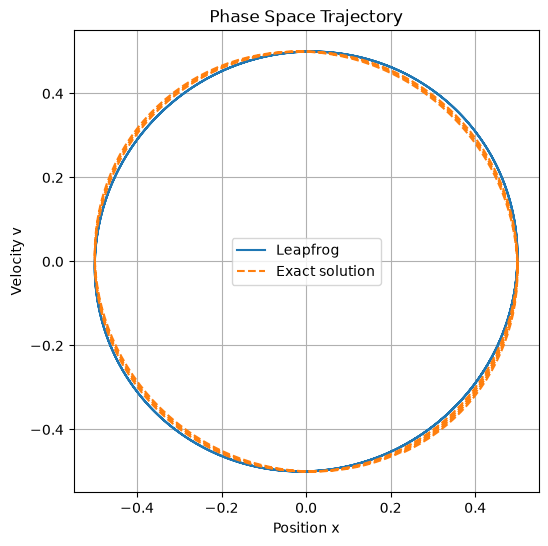

In [1]:
##Leap Frog Integration Method 
import numpy as np
import matplotlib.pyplot as plt

## Simple Leap Frog Integration for 1 iteration as asked in 1st requriement 
def leapfrog(x, v, h):
    v_half = v - 0.5 * h * x
    x_new = x + h * v_half
    v_new = v_half - h * x_new

    return x_new, v_new, v_half

x = np.array([0.5, 1.0, 1.5])
v = np.array([0.0, 0.2, -0.1])
h = 0.05

x_new, v_new, v_half = leapfrog(x, v, h)
print("New positions:", x_new)
print("New velocities:", v_new)
print("Half Time Step:", v_half)

##MAIN PART
##Comparision with Exact Solution
#Initial Conditions
omega_p = 1
h = 0.05
t = [0, 20]
n = int((t[1] - t[0]) / h)

timesteps_x = np.linspace(t[0], t[1], n+1)
timesteps_v = np.linspace(t[0], t[1], n)

x = np.zeros(n+1)
v_half = np.zeros(n)

x[0] = 0.5
v[0] = 0.0
v_minus_half = v[0] + 0.5*h*omega_p**2*x[0]

def leapfrog1(x, v, h):
    v_new = v - h * omega_p**2 * x
    x_new = x + h * v_new
    return x_new, v_new

for i in range(n):
    v_half[i] = v_minus_half
    x[i+1], v_minus_half = leapfrog1(x[i], v_minus_half, h)

# Exact solutions at corresponding times
x_exact = 0.5 * np.cos(omega_p * timesteps_x)
v_exact = -0.5 * np.sin(omega_p * timesteps_v)

# Plot position at whole time levels
plt.figure(figsize=(6, 3))
plt.plot(timesteps_x, x, label="Leapfrog")
plt.plot(timesteps_x, x_exact, "--", label="Exact solution")
plt.xlabel("Time (s)")
plt.ylabel("Position x")
plt.title("Position vs Time")
plt.legend()
plt.grid(True)
plt.show()

# Plot velocity at half time levels
plt.figure(figsize=(6, 3))
plt.plot(timesteps_v, v_half, label="Leapfrog")
plt.plot(timesteps_v, v_exact, "--", label="Exact solution")
plt.xlabel("Time (s)")
plt.ylabel("Velocity v")
plt.title("Half-Step Velocity vs Time")
plt.legend()
plt.grid(True)
plt.show()

## Phase Space Trajectory 
plt.figure(figsize=(6, 6))
plt.plot(x[0:n], v_half, label="Leapfrog")
plt.plot(x_exact[0:n], v_exact, "--", label="Exact solution")
plt.xlabel("Position x")
plt.ylabel("Velocity v")
plt.title("Phase Space Trajectory")
plt.legend()
plt.grid(True)
plt.show()

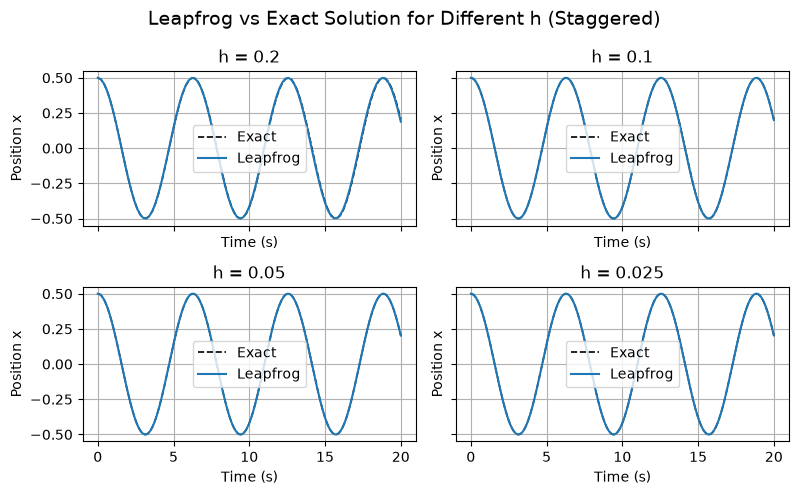

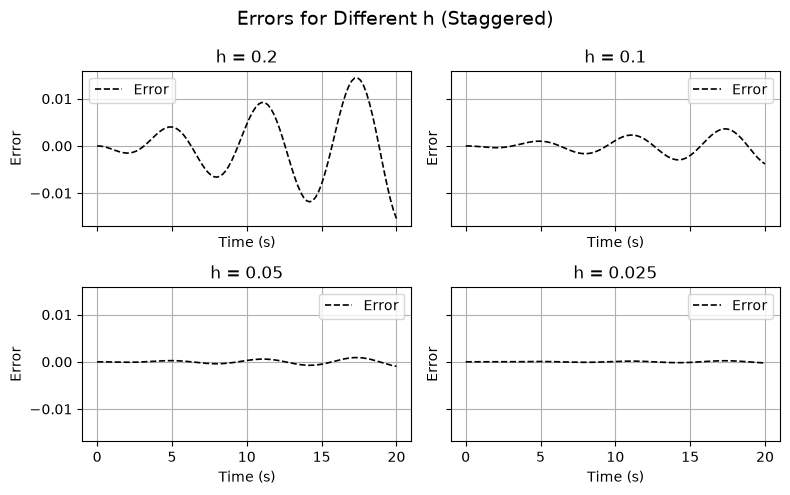

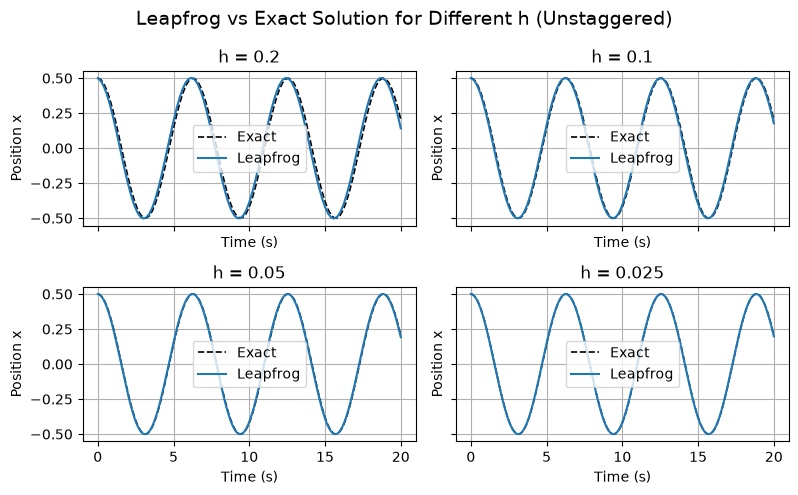

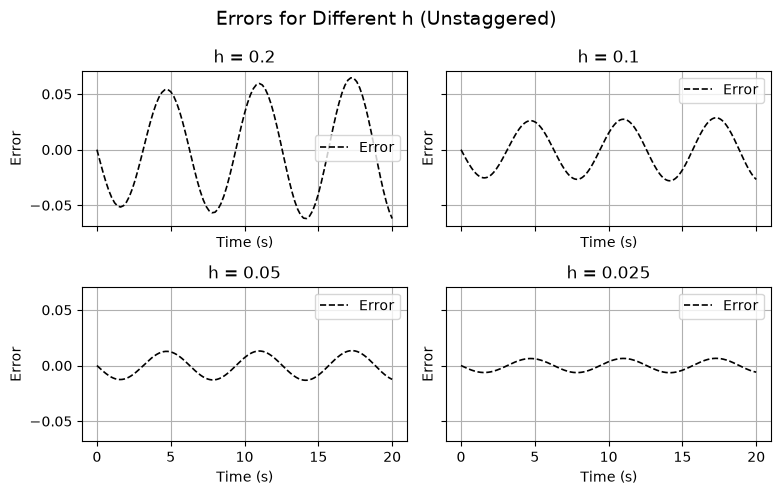

Staggered p:   [2.01270879 2.00321874 2.00080727]
Unstaggered p: [1.17313464 1.09502899 1.04937002]


In [2]:
## Convergence Analysis 
#Staggered Start
t = [0, 20]
h_values = [0.2, 0.1, 0.05, 0.025]
x2 = {}
time = {}
x_exact_arr = {}
err_arr_1 = {}

for h in h_values:
    n_step = int((t[1] - t[0])/ h)
    timestep = np.linspace(t[0], t[1], n_step + 1)

    x_exact_1 = 0.5 * np.cos(omega_p * timestep)
    x1 = np.zeros(n_step + 1)
    v_half1 = np.zeros(n_step)

    x1[0] = 0.5
    v_0 = 0
    v_minus_half1 = v_0 + 0.5 * h * omega_p**2 * x1[0]

    for j in range(n_step):
        v_half1[j] = v_minus_half1
        x1[j+1], v_minus_half1 = leapfrog1(x1[j], v_minus_half1, h)

    x2[h] = x1
    time[h] = timestep
    x_exact_arr[h] = x_exact_1

    err_arr = np.zeros(n_step + 1)
    err_arr = (x1 - x_exact_1)
    err_arr_1[h] = err_arr
    
fig, axs = plt.subplots(2, 2, figsize=(8, 5), sharex=True, sharey=True)
for i in range(len(h_values)):
    ax = axs.flat[i]
    h = h_values[i]
    ax.plot(time[h], x_exact_arr[h], "k--", linewidth=1.2, label="Exact")
    ax.plot(time[h], x2[h], label="Leapfrog")
    ax.set_title(f"h = {h}")
    ax.set_xlabel("Time (s)")
    ax.set_ylabel("Position x")
    ax.legend()
    ax.grid(True)

fig.suptitle("Leapfrog vs Exact Solution for Different h (Staggered)", fontsize=14)
plt.tight_layout()
plt.show()

fig, axs = plt.subplots(2, 2, figsize=(8, 5), sharex=True, sharey=True)
for i in range(len(h_values)):
    ax = axs.flat[i]
    h = h_values[i]
    ax.plot(time[h], err_arr_1[h], "k--", linewidth=1.2, label="Error")
    ax.set_title(f"h = {h}")
    ax.set_xlabel("Time (s)")
    ax.set_ylabel("Error")
    ax.legend()
    ax.grid(True)

fig.suptitle("Errors for Different h (Staggered)", fontsize=14)
plt.tight_layout()
plt.show()

#Unstaggered Start 
x21 = {}
time1 = {}
x_exact_arr1 = {}
err_arr_2 = {}

for h in h_values:
    n_step = int((t[1] - t[0])/ h)
    timestep = np.linspace(t[0], t[1], n_step + 1)

    x_exact_1 = 0.5 * np.cos(omega_p * timestep)
    x1 = np.zeros(n_step + 1)
    v_half1 = np.zeros(n_step)

    x1[0] = 0.5
    v_0 = 0
    v_minus_half1 = v_0

    for j in range(n_step):
        v_half1[j] = v_minus_half1
        x1[j+1], v_minus_half1 = leapfrog1(x1[j], v_minus_half1, h)

    x21[h] = x1
    time1[h] = timestep
    x_exact_arr1[h] = x_exact_1

    err_arr1 = np.zeros(n_step + 1)
    err_arr1 = (x1 - x_exact_1)
    err_arr_2[h] = err_arr1
    
fig, axs = plt.subplots(2, 2, figsize=(8, 5), sharex=True, sharey=True)
for i in range(len(h_values)):
    ax = axs.flat[i]
    h = h_values[i]
    ax.plot(time[h], x_exact_arr1[h], "k--", linewidth=1.2, label="Exact")
    ax.plot(time[h], x21[h], label="Leapfrog")
    ax.set_title(f"h = {h}")
    ax.set_xlabel("Time (s)")
    ax.set_ylabel("Position x")
    ax.legend()
    ax.grid(True)

fig.suptitle("Leapfrog vs Exact Solution for Different h (Unstaggered)", fontsize=14)
plt.tight_layout()
plt.show()

fig, axs = plt.subplots(2, 2, figsize=(8, 5), sharex=True, sharey=True)
for i in range(len(h_values)):
    ax = axs.flat[i]
    h = h_values[i]
    ax.plot(time1[h], err_arr_2[h], "k--", linewidth=1.2, label="Error")
    ax.set_title(f"h = {h}")
    ax.set_xlabel("Time (s)")
    ax.set_ylabel("Error")
    ax.legend()
    ax.grid(True)

fig.suptitle("Errors for Different h (Unstaggered)", fontsize=14)
plt.tight_layout()
plt.show()

##Error Ratio for Staggered and Unstaggered Start
e1 = []
e2 = []
for h in h_values:
    e1.append(np.max(np.abs(err_arr_1[h])))
    e2.append(np.max(np.abs(err_arr_2[h])))

e1 = np.array(e1)
e2 = np.array(e2)

print("Staggered p:  ", np.log2(e1[:-1] / e1[1:]))
print("Unstaggered p:", np.log2(e2[:-1] / e2[1:]))

### Velocity $v$ can be eliminated to show the scheme in central difference formula 

We have the 2 uncoupled equation from the LeapFrog Integration Method:

$$
\begin{aligned}
\mathbf{v}_{n+1/2} &= \mathbf{v}_{n-1/2} + ha(x), \\
\mathbf{x}_{n+1} &= \mathbf{x}_n + h\mathbf{v}_{n+1/2}.
\end{aligned}
$$

where 
$
a(x) = -\omega_p^2 \mathbf{x}_{n}
$

Velocity can be written in form of position and time step $h$ as:
$$
\mathbf{v}_{n+1/2} = \frac{x_{n+1} - x_{n}}{h}
$$ 
and 

$$
\mathbf{v}_{n-1/2} = \frac{x_{n} - x_{n-1}}{h}
$$ 

Put the velocity as a function of postion in orignal Leapfrog Equation. This will change the equation as:
$$
\frac{x_{n+1} - x_{n}}{h} = \frac{x_{n} - x_{n-1}}{h} - h\omega_p^2 \mathbf{x}_{n}
$$

Rearranging this:
$$
\frac{x_{n+1} - x_{n}}{h} - \frac{x_{n} - x_{n-1}}{h} = - h\omega_p^2 \mathbf{x}_{n}
$$

$$
\frac{x_{n+1} - x_{n} - x_{n} + x_{n-1}}{h} = - h\omega_p^2 \mathbf{x}_{n}
$$

$$
x_{n+1} - 2x_{n}  + x_{n-1} = - h^2\omega_p^2 \mathbf{x}_{n}
$$

This is the central difference form of the LeapFrog Integration. 

### Stability Limit 
We assume a solution of the central difference equation of the form: $x_{n} = r^{n}$
The central difference form becomes: 

$$
r^{n+1} + (h^2\omega_p^2 - 2)r^{n}  + r^{n-1} = 0
$$

Dividing by $r^{n-1}$, this will give us: 

$$
r^{2} + (h^2\omega_p^2 - 2)r + 1 = 0
$$ 

The roots can be found by solving this quadratic, we get:

$$
r_{1,2} = \frac{2 - h^2\omega_p^2 \pm \sqrt{(h^2\omega_p^2 - 2)^2 - 4}}{2}
$$

For stability, $\sqrt{(h^2\omega_p^2 - 2)^2 - 4} < 0$:
we get:

$$
(h^2\omega_p^2 - 2)^2 < 4
$$

$$
-2 < (h^2\omega_p^2 - 2) < 2
$$

$$
0 < h^2\omega_p^2 < 4
$$

$$
0 < h\omega_p < 2
$$

By taking the right hand limit, we can get the stability limit:
$$
h\omega_p < 2
$$